In [ ]:
'''
hyperparameters for decision tree
    1 - max_depth [MOST IMPORTANT]
    2 - min_samples split  - min samples for a node to split further
    3 - min samples leaf - min samples required in a leaf node 

DT As a regressor - Just like linear regression, DT can be used for regression as well 
    Instead of entropy mse is the deciding metric for regression to choose splits
    Steps: Taking example of finding a root node with correct split
    1 - For all features, and for all thresholds, splits are done
    2 - To decide the best threshold, mse is calculated for the root (mse for mean against actual values)
    3 - mse is also calculated for the 2 leafs of the next branch (actual values against means of respective branches)
    4 - Weighted mean is calculated for the 2 leaves
    5 - mse decrease is calculated
    6 - based on the above calculations, best feature and best threshold is decided

    mse calculation example: Let's say that we have 10 samples with mean of 500.
    (30,40,50,60,70,930,940,950,960,970) 

    - Current mse is 202,700
    - Let's say we split at 500, 2 sets are created: (30,40,50,60,70) and (930,940,950,960,970)
    - mse 1= 200 and mse2 = 200. Weighted mse of both is 200
    - Hence, net net mse is reduced by doing this split 

'''

7

# Hyperparameter tuning using kfold cross validation

In [2]:
import pandas as pd
import numpy as np

!gdown 19L3rYatfhbBL1r5MHrv-p_oM2wlvrhqk
!gdown 1OHLKJwA3qZopKPvlKoRldM6BvA1A4dYF
!gdown 1N7O_fWCTJLu8SIa_paKcDEzllgpMk8sK
!gdown 12Bh2AN8LcZAlg20ehpQrEWccUDaSdsOG

Downloading...
From: https://drive.google.com/uc?id=19L3rYatfhbBL1r5MHrv-p_oM2wlvrhqk
To: c:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.4_ml_decision_trees_2\preprocessed_X_sm.pickle

  0%|          | 0.00/534k [00:00<?, ?B/s]
100%|██████████| 534k/534k [00:00<00:00, 9.54MB/s]
Downloading...
From: https://drive.google.com/uc?id=1OHLKJwA3qZopKPvlKoRldM6BvA1A4dYF
To: c:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.4_ml_decision_trees_2\X_test.pickle

  0%|          | 0.00/111k [00:00<?, ?B/s]
100%|██████████| 111k/111k [00:00<00:00, 1.42MB/s]
Downloading...
From: https://drive.google.com/uc?id=1N7O_fWCTJLu8SIa_paKcDEzllgpMk8sK
To: c:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.4_ml_decision_trees_2\y_sm.pickle

  0%|          | 0.00/15.4k [00:00<?, ?B/s]
100%|██████████| 15.4k/15.4k [00:00<00:00, 49.4MB/s]
Failed to retrieve file url:

	Cannot retrieve the public link of the file. You may need to chang

In [5]:
import pickle
import pandas as pd
# Load data (deserialize)
with open('preprocessed_X_sm.pickle', 'rb') as handle:
    X_train = pd.read_pickle(handle)

with open('X_test.pickle', 'rb') as handle:
    X_test = pd.read_pickle(handle)

with open('y_sm.pickle', 'rb') as handle:
    y_train = pd.read_pickle(handle)

with open('y_test.pickle', 'rb') as handle:
    y_test = pd.read_pickle(handle)

In [25]:
from sklearn.model_selection import KFold,cross_validate
from sklearn.tree import DecisionTreeClassifier
import seaborn as sns

In [7]:
kf=KFold(n_splits=10)

In [23]:

test_scores=[]
train_scores=[]
for i in np.arange(1,100):
    score=cross_validate(DecisionTreeClassifier(max_depth=i),X_train,y_train,return_train_score=True,cv=kf)
    train_scores.append(np.mean(score['train_score']))
    test_scores.append(np.mean(score['test_score']))




5


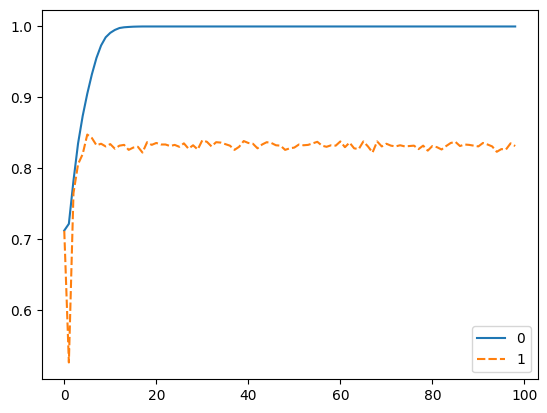

In [ ]:
sns.lineplot([train_scores,test_scores])

print(np.argmax(test_scores))

# 5 LOOKS LIKE A REASONABLE FINAL NUMBER

# Feature importance and interpretability: Seems irrelevant- check from the notes

# Decision tree as a regressor

In [37]:
import pandas as pd 
from sklearn.model_selection import train_test_split, KFold,cross_validate
from sklearn.tree import DecisionTreeRegressor
import pandas as pd
import numpy as np 
import seaborn as sns

In [1]:
!gdown 176WcJFfaSz3YkO1TiGEg_EqWgJ4YQEwO

Downloading...
From: https://drive.google.com/uc?id=176WcJFfaSz3YkO1TiGEg_EqWgJ4YQEwO
To: c:\Users\Mayank Bhatia\Documents\GitHub\DSML\14_ml_supervised_algorithms\14.4_ml_decision_trees_2\regData.csv

  0%|          | 0.00/13.4k [00:00<?, ?B/s]
100%|██████████| 13.4k/13.4k [00:00<00:00, 44.8MB/s]


In [5]:
regression_data = pd.read_csv('regData.csv')

In [29]:
x=pd.DataFrame(regression_data['X'])
y=regression_data['Y']

In [30]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.25)

In [41]:

kf=KFold(n_splits=3)
train_scores=[]
test_scores=[]
for i in np.arange(1,11):
    cv_acc_results=cross_validate(estimator=DecisionTreeRegressor(max_depth=i,random_state=7,min_samples_split=10,min_samples_leaf=20),X=x_train,y=y_train,cv=kf,return_train_score=True)
    train_scores.append(cv_acc_results['train_score'].mean())
    test_scores.append(cv_acc_results['test_score'].mean())



In [45]:
print(test_scores)
print(train_scores)

[np.float64(0.5980226691147309), np.float64(0.9556311070777342), np.float64(0.9554247611493265), np.float64(0.9553435989936573), np.float64(0.9553094571650718), np.float64(0.9553094571650718), np.float64(0.9553094571650718), np.float64(0.9553094571650718), np.float64(0.9553094571650718), np.float64(0.9553094571650718)]
[np.float64(0.6208780685695064), np.float64(0.9911666170155092), np.float64(0.9915724777030036), np.float64(0.9916845919205098), np.float64(0.9917408817722734), np.float64(0.9917408817722734), np.float64(0.9917408817722734), np.float64(0.9917408817722734), np.float64(0.9917408817722734), np.float64(0.9917408817722734)]


# Assignment

In [2]:
import numpy as np 

In [6]:
m=np.array([1,0,0,0,0,0,1,0,1,1])

In [10]:
counts=np.unique(m,return_counts=True)

In [12]:
counts[1].sum()

np.int64(10)

In [14]:
entropy=0
for i in (np.arange(len(counts[1]))):
    entropy+=(counts[1][i]/counts[1].sum())*np.log2((counts[1][i]/counts[1].sum()))
